# 4.18
Give the following data sequence with a length of 6:
x(0)=0, x(1)=0.2, x(2)=0, x(3)=-0.2, x(4)=0, x(5)=0.2
Compute the windowed sequence x_w(n) using

a) Triangular window function

b) Hamming window function

c) Hanning window function

triangular window: [0.  0.4 0.8 0.8 0.4 0. ]
hamming window: [0.08       0.39785218 0.91214782 0.91214782 0.39785218 0.08      ]
hanning window: [0.        0.3454915 0.9045085 0.9045085 0.3454915 0.       ]


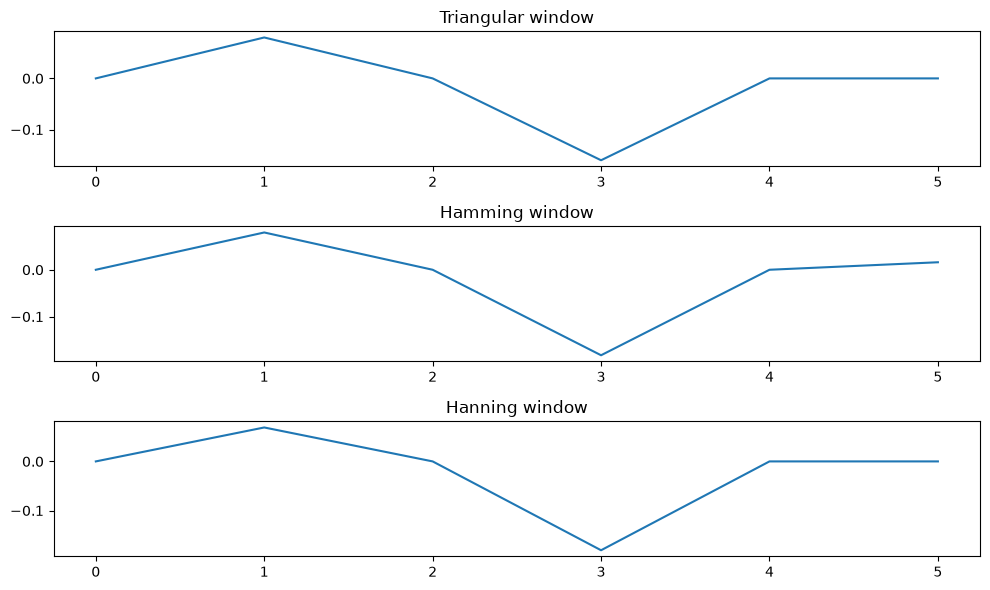

triangular window: [ 0.    0.08  0.   -0.16  0.    0.  ]
hamming window: [ 0.          0.07957044  0.         -0.18242956  0.          0.016     ]
hanning window: [ 0.         0.0690983  0.        -0.1809017  0.         0.       ]


In [19]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([0, 0.2, 0, -0.2, 0, 0.2])
N = len(x)

w_tri = np.bartlett(N)
w_ham = np.hamming(N)
w_han = np.hanning(N)


print(f"triangular window: {w_tri}")
print(f"hamming window: {w_ham}")
print(f"hanning window: {w_han}")

# Plot the windows
fig, ax = plt.subplots(3, 1, figsize=(10, 6))
ax[0].plot(x*w_tri, label='Triangular window')
ax[0].set_title('Triangular window')
ax[1].plot(x*w_ham, label='Hamming window')
ax[1].set_title('Hamming window')
ax[2].plot(x*w_han, label='Hanning window')
ax[2].set_title('Hanning window')
plt.tight_layout()
plt.show()

print(f"triangular window: {x * w_tri}")
print(f"hamming window: {x * w_ham}")
print(f"hanning window: {x * w_han}")


# 4.20
Given a sinusoid
$$
x(n) = 2*sin(2000 * 2 \pi * \frac{n}{8000})
$$
obtained by using the sampling rate of $f_s=8000Hz$, we apply the DFT to compute the ampltude spectrum.

a) Determine the frequency resolution when the data length is 100 samples. Without using the window function, is there any spectral leakage in the computed spectrum? Explain.

Frekvensopløsningen bliver $\Delta f = f_s /N = 8000/100 = 80Hz$

Da 2000Hz rammer en bin (altså da $N * 2000/8000 = 25$ er et heltal) er der in spektral lækage.


b) Determine the frequency resolution when the data length is 73 samples. Without using the window functions, is there any spectral leakage in the computed spectum? Explain.

Når $N=73$ kommer der til at være spektral lækage idet frekvensopløsningen er $\Delta f = \frac{8000}{73}\approx 109.59Hz$ og $\frac{2000}{109.59}=18.25$
Altså rammer frekvensen på 2000Hz ikke i en bin præcist hvilket vil sige at der opstår spektral lækage.

Dette er illustreret nedenfor


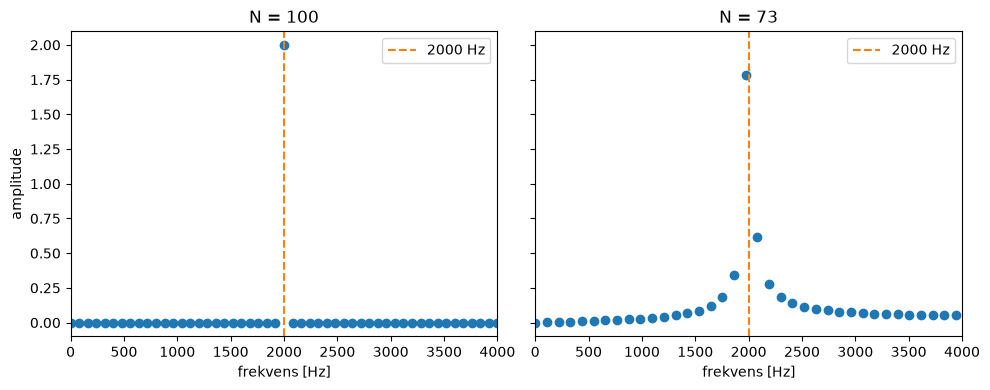

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fs = 8000
f0 = 2000

def amplitude_spectrum(N):
    n = np.arange(N)
    x = 2 * np.sin(2 * np.pi * f0 * n / fs)
    X = np.fft.rfft(x)
    freq = np.fft.rfftfreq(N, d=1 / fs)
    amp = np.abs(X) * 2 / N
    return freq, amp


fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, N in zip(ax, (100, 73)):
    a.plot(*amplitude_spectrum(N), "o")
    a.axvline(f0, color="C1", ls="--", label="2000 Hz")
    a.set_xlim(0, fs / 2)
    a.set_title(f"N = {N}")
    a.set_xlabel("frekvens [Hz]")
    a.legend()
ax[0].set_ylabel("amplitude")
fig.tight_layout()
plt.show()
